In [9]:
import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import glob
from PIL import Image
from skytrack.visdrone import load_annotations, draw_boxes
ROOT = Path.cwd().parent                       # the SkyTrack folder
VAL_DIR = ROOT / "data/raw/VisDrone2019-DET-val"
IMG_DIR = VAL_DIR / "images"
ANN_DIR = VAL_DIR / "annotations"

In [10]:
img_data = cv2.imread(IMG_DIR/'0000001_02999_d_0000005.jpg')
annotation = np.loadtxt(ANN_DIR/'0000001_02999_d_0000005.txt', delimiter=",")
print(img_data.shape, img_data.dtype)

(1080, 1920, 3) uint8


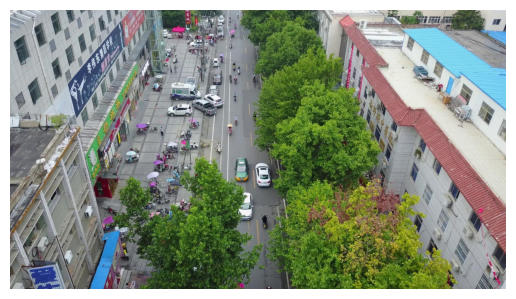

In [11]:
img_rgb = cv2.cvtColor(img_data, cv2.COLOR_BGR2RGB)
plt.imshow(img_rgb)
plt.axis("off")
plt.show()

In [12]:
frames_df = load_annotations(ANN_DIR, IMG_DIR)
    
    
    

#total_counts = frames_df["category"].value_counts().sort_index()
#print(total_counts)
print("Median size:", frames_df["size"].median())
print("Median size reduced to 640 px:", frames_df["size_640"].median())
print("Share of boxes under 32 px:", (frames_df["size"] < 32).mean())
print("Share of reduced boxes under 8 px:", (frames_df["size_640"] < 8).mean())
print("Median size of reduced boxes by", frames_df.groupby("category")["size_640"].median())

Median size: 23.065125189341593
Median size reduced to 640 px: 11.426091000668407
Share of boxes under 32 px: 0.6773133510916378
Share of reduced boxes under 8 px: 0.30150115760910157
Median size of reduced boxes by category
0     17.876160
1      8.404975
2      8.459052
3     10.049015
4     15.607646
5     16.329932
6     19.293245
7     14.832397
8     14.335573
9     16.915012
10     9.921911
11    21.089781
Name: size_640, dtype: float64


- 68% of objects are small by the COCO definition (under 32px), even at full resolution

- 30% of objects shrink below 8px at 650 input

- People/pedestrians are hit hardest, they have a median of about 8.4px

- Roughly half of all humans in the dataset fall below 8px

- Motorbikes (10) and bicycles (3) are close behind at about 10px

- Cars and vans fare better at about 16px

- Prediction:
- The pretrained model will do worse on pedestrians, people, bicycles and motorbikes.
- It will perform better on cars/vans

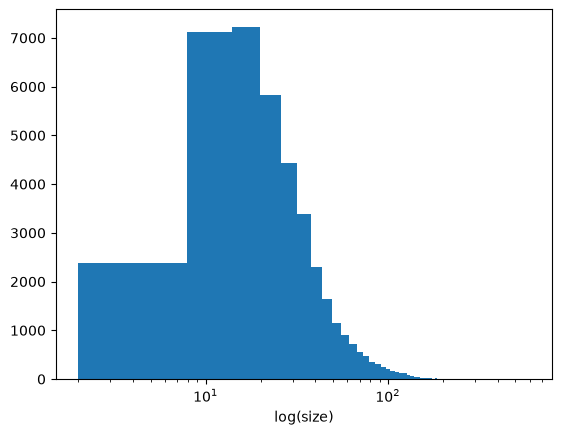

In [13]:
plt.hist(frames_df["size"], bins=100)
plt.xscale("log")
plt.xlabel("log(size)")
plt.show()

In [14]:
frames_df.groupby("category")["size"].median()

category
0     34.885524
1     17.175539
2     16.733201
3     20.784610
4     32.496154
5     33.585711
6     38.613293
7     28.372522
8     29.291637
9     35.242020
10    20.000000
11    40.923607
Name: size, dtype: float64

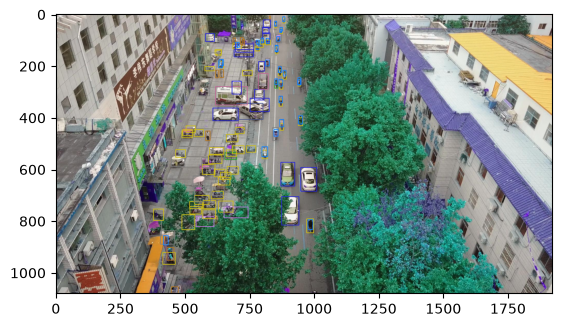

In [20]:
vis = draw_boxes(img_data, annotation)
plt.imshow(vis)

There is clear class imbalance (at least in the first image)